Basic Machine Learning Implementation - <10/23/26> - <Roseya1362) 

In [2]:
# import necessary Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from datetime import datetime
from IPython.display import display, Markdown
todays_date = datetime.now().strftime("%Y-%m-%d")
student_id = "Roseya1362"
# load the Credit card data
data = pd.read_csv("Credit_card_data.csv")
# Display the first few rows to understand what the data looks like
display(Markdown("Data: Load the Dataset"))
display(Markdown(f"Date: {todays_date}"))
display(Markdown(f"student ID: {student_id}"))
display(data.head())
print ("Dataset shape:", data.shape)

Data: Load the Dataset

Date: 2026-11-03

student ID: Roseya1362

,card,reports,age,income,share,expenditure,owner,selfemp,dependents,months,majorcards,active
0,yes,0.0,37.66667,4.5200,0.033270,124.983300,yes,no,3.0,54,1,12.0
1,yes,0.0,33.25000,2.4200,0.005217,9.854167,no,no,3.0,34,1,13.0
2,yes,0.0,33.66667,4.5000,0.004156,15.000000,yes,no,4.0,58,1,5.0
3,yes,0.0,30.50000,2.5400,0.065214,137.869200,no,no,0.0,25,1,7.0
4,yes,0.0,32.16667,9.7867,0.067051,546.503300,yes,no,2.0,64,1,5.0


Dataset shape: (1319, 12)


I loaded the Credit Card dataset into Python using the pandas library. The dataset contains 1,319 rows and 12 columns, including customer age, income, credit card ownership, and expenditure. I displayed the first five rows to understand the data structure. This step helps me prepare the dataset for analysis and machine learning.

In [3]:
display(Markdown("### Step: Summary Statistics"))
display(Markdown(f"Date: {todays_date}"))
display(Markdown(f"Student ID: {student_id}"))

# Display dataset information
print("Dataset Information:")
print(data.info())

# Display summary statistics
print("/nSummary Statistics:")
display(data.describe())

### Step: Summary Statistics

Date: 2026-11-03

Student ID: Roseya1362

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1319 entries, 0 to 1318
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   card         1319 non-null   object 
 1   reports      1311 non-null   float64
 2   age          1319 non-null   float64
 3   income       1319 non-null   float64
 4   share        1319 non-null   float64
 5   expenditure  1319 non-null   float64
 6   owner        1319 non-null   object 
 7   selfemp      1312 non-null   object 
 8   dependents   1318 non-null   float64
 9   months       1319 non-null   int64  
 10  majorcards   1319 non-null   int64  
 11  active       1311 non-null   float64
dtypes: float64(7), int64(2), object(3)
memory usage: 123.8+ KB
None
/nSummary Statistics:


,reports,age,income,share,expenditure,dependents,months,majorcards,active
count,1311.000000,1319.000000,1319.000000,1319.000000,1319.000000,1318.000000,1319.000000,1319.000000,1311.000000
mean,0.457666,33.213103,3.365376,0.068732,185.057071,0.994689,55.267627,0.817286,7.017544
std,1.348848,10.142783,1.693902,0.094656,272.218917,1.247918,66.271746,0.386579,6.319158
min,0.000000,0.166667,0.210000,0.000109,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,25.416670,2.243750,0.002316,4.583333,0.000000,12.000000,1.000000,2.000000
50%,0.000000,31.250000,2.900000,0.038827,101.298300,1.000000,30.000000,1.000000,6.000000
75%,0.000000,39.416670,4.000000,0.093617,249.035800,2.000000,72.000000,1.000000,11.000000
max,14.000000,83.500000,13.500000,0.906320,3099.505000,6.000000,540.000000,1.000000,46.000000


In [4]:
display(Markdown("### Step: Missing Values"))
display(Markdown(f"Date: {todays_date}"))
display(Markdown(f"Student ID: {student_id}"))

# Display missing values
print("/nMising Values:")
print(data.isnull().sum())

### Step: Missing Values

Date: 2026-11-03

Student ID: Roseya1362

/nMising Values:
card           0
reports        8
age            0
income         0
share          0
expenditure    0
owner          0
selfemp        7
dependents     1
months         0
majorcards     0
active         8
dtype: int64


Missing values were checked in the credit card dataset to identify columns with incomplete data before building the machine learning models. This step is important because missing data can affect model accuracy and reliability.

Missing Values Summary

Column

Number of Missing Values

card

0

reports

8

age

0

income

0

share

0

expenditure

0

owner

0

selfemp

7

dependents

1

months

0

majorcards

0

active

8

Findings

The analysis identified missing values in three columns: reports has 8 missing values, selfemp has 7 missing values, and dependents has 1 missing value. The remaining nine columns have no missing values.

Conclusion and Next Steps

The dataset contains missing values that should be addressed before model training. I will handle the missing values by using an appropriate imputation method, such as the median for numerical variables and the mode for categorical variables. The imputation values will be calculated using the training data to prevent data leakage. After handling the missing values, I will verify that the dataset is complete and ready for the next stages

In [5]:
display(Markdown("### Step: Classification model"))
display(Markdown(f"Date: {todays_date}"))
display(Markdown(f"Student ID: {student_id}"))

import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score, precision_score,
    recall_score, f1_score,
    confusion_matrix, classification_report
)

tf.keras.utils.set_random_seed(42)

# Select classification features
features = [
    "reports", "age", "income", "owner",
    "selfemp", "dependents", "months",
    "majorcards", "active"
]

X = data[features].copy()
y = data["card"].str.lower().map({"no": 0, "yes": 1})

# Remove rows without a target
valid = y.notna()
X = X.loc[valid]
y = y.loc[valid].astype(int)

numeric = X.select_dtypes(include=np.number).columns.tolist()
categorical = X.select_dtypes(exclude=np.number).columns.tolist()

preprocessor = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), numeric),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore",
                                  sparse_output=False))
    ]), categorical)
])

# Split into training and testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2,
    random_state=42, stratify=y
)

X_train = preprocessor.fit_transform(X_train)
X_test = preprocessor.transform(X_test)

# Build neural network
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(X_train.shape[1],)),
    tf.keras.layers.Dense(32, activation="relu"),
    tf.keras.layers.Dense(16, activation="relu"),
    tf.keras.layers.Dense(1, activation="sigmoid")
])

# Compile
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# Train
history = model.fit(
    X_train, y_train,
    epochs=30,
    batch_size=32,
    validation_split=0.2,
    verbose=1
)

# Evaluate
loss, accuracy = model.evaluate(X_test, y_test, verbose=0)

predictions = (
    model.predict(X_test, verbose=0).ravel() >= 0.5
).astype(int)

print("Test Accuracy:", round(accuracy, 4))
print("Test Loss:", round(loss, 4))
print("Precision:", round(precision_score(y_test, predictions,
                                          zero_division=0), 4))
print("Recall:", round(recall_score(y_test, predictions,
                                    zero_division=0), 4))
print("F1 Score:", round(f1_score(y_test, predictions,
                                  zero_division=0), 4))
print("\nClassification Report:")
print(classification_report(y_test, predictions,
                            zero_division=0))
print("Confusion Matrix:")
print(confusion_matrix(y_test, predictions))






### Step: Classification model

Date: 2026-11-03

Student ID: Roseya1362

Epoch 1/30
27/27 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.6220 - loss: 0.6676 - val_accuracy: 0.7820 - val_loss: 0.5779
Epoch 2/30
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8128 - loss: 0.5381 - val_accuracy: 0.7915 - val_loss: 0.5229
Epoch 3/30
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8211 - loss: 0.4832 - val_accuracy: 0.8009 - val_loss: 0.4930
Epoch 4/30
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8246 - loss: 0.4480 - val_accuracy: 0.8104 - val_loss: 0.4694
Epoch 5/30
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8306 - loss: 0.4200 - val_accuracy: 0.8246 - val_loss: 0.4501
Epoch 6/30
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8341 - loss: 0.3984 - val_accuracy: 0.8531 - val_loss: 0.4370
Epoch 7/30
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8377 - loss: 0.3831 - val_accuracy: 0.8578 - val_loss: 0.4282
Epoch 8/30
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8424 - loss: 0.3718 - val_accuracy: 0.8578 - val_loss:

In this step, I trained a neural network classification model using the Credit Card dataset. The model was trained for 30 epochs to learn patterns in the data and improve its predictions,
The results show that the training accuracy increased from 61.73% in the first epoch to approximately 84.60% by epoch 10. The training loss also decreased from 0.6634 t0 0,3534, showing that the model was learning.
The validation accuracy improved from 78.67% to 86.26% by epoch 10. This suggests that the model was improving its prediction on validation data.


### Step:Visualize Classification training

Date: 2026-11-03

Student ID: Roseya1362

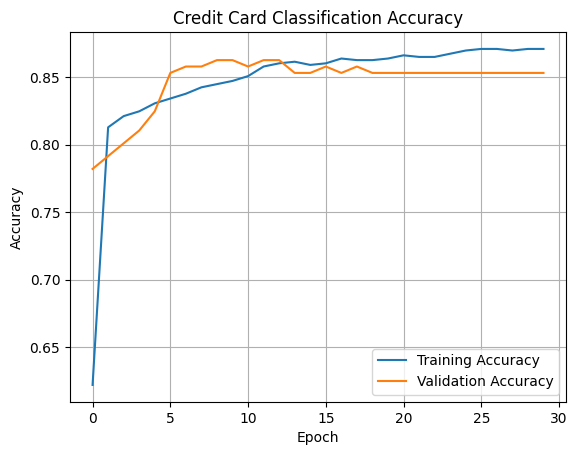

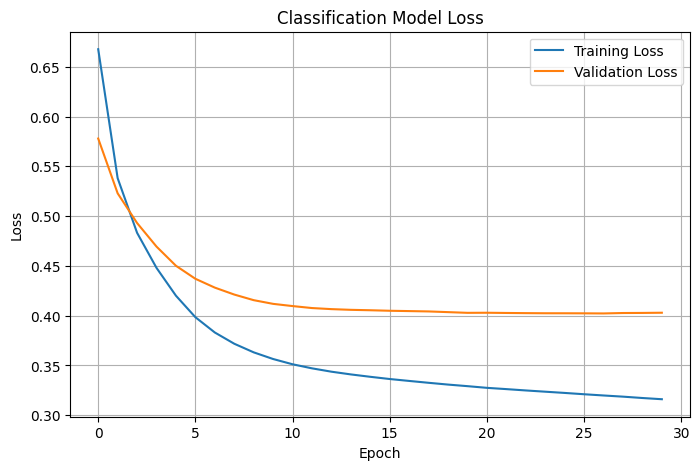

In [6]:
display(Markdown("### Step:Visualize Classification training"))
display(Markdown(f"Date: {todays_date}"))
display(Markdown(f"Student ID: {student_id}"))

plt.plot(history.history["accuracy"],
         label="Training Accuracy")
plt.plot(history.history["val_accuracy"],
         label="Validation Accuracy")

plt.title("Credit Card Classification Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("Classification Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

The two graphs show the performance of my neural network classification model using the Credit card dataset.
Accuracy Graph: The training accuracy increased to approximately 86%, while the validation accuracy reached approximately 84%. This shows that the model improved during training.
Loss Graph: The training loss decreased from approximately 0.66 to 0.31, while the validation loss decreased from approximately 0.57 to 0.40.
This shows that the model made fewer prediction errors as training continued


In [7]:
display(Markdown("### Step: Regression model"))
display(Markdown(f"Date: {todays_date}"))
display(Markdown(f"Student ID: {student_id}"))


from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

# Select predictors
reg_features = [
    "reports", "age", "income", "owner",
    "selfemp", "dependents", "months",
    "majorcards", "active"
]

reg_data = data.dropna(subset=["expenditure"]).copy()

X_reg = reg_data[reg_features]
y_reg = reg_data["expenditure"]

X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(
    X_reg, y_reg, test_size=0.2, random_state=42
)

from sklearn.base import clone

reg_preprocessor = clone(preprocessor)

X_train_r = reg_preprocessor.fit_transform(X_train_r)
X_test_r = reg_preprocessor.transform(X_test_r)

# Build regression neural network
reg_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(X_train_r.shape[1],)),
    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dense(32, activation="relu"),
    tf.keras.layers.Dense(1, activation="linear")
])

# Compile
reg_model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

# Train
reg_history = reg_model.fit(
    X_train_r, y_train_r,
    epochs=50,
    batch_size=32,
    validation_split=0.2,
    verbose=1
)

# Evaluate
reg_loss, reg_mae = reg_model.evaluate(
    X_test_r, y_test_r, verbose=0
)

reg_predictions = reg_model.predict(
    X_test_r, verbose=0
).ravel()

print("Mean Squared Error:",
      mean_squared_error(y_test_r, reg_predictions))
print("Mean Absolute Error:",
      mean_absolute_error(y_test_r, reg_predictions))
print("R2 Score:",
      r2_score(y_test_r, reg_predictions))

### Step: Regression model

Date: 2026-11-03

Student ID: Roseya1362

Epoch 1/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 103199.1250 - mae: 184.8847 - val_loss: 106229.9609 - val_mae: 182.8734
Epoch 2/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 102183.0625 - mae: 183.4316 - val_loss: 104798.0078 - val_mae: 180.8615
Epoch 3/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 100215.7266 - mae: 180.7201 - val_loss: 102081.6797 - val_mae: 177.2271
Epoch 4/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 96601.1719 - mae: 175.9624 - val_loss: 97406.0156 - val_mae: 171.4476
Epoch 5/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 90777.3047 - mae: 168.4847 - val_loss: 90552.2578 - val_mae: 164.1493
Epoch 6/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 82929.1875 - mae: 159.7249 - val_loss: 82361.4141 - val_mae: 158.8804
Epoch 7/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 74617.9062 - mae: 153.9967 - val_loss: 75103.4297 - val_mae: 158.3933
Epoch 8/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 68320.8281 - mae: 154.7979 - val_loss: 7

Explanation: I used a TensorFlow neural network regressor model to predict credit card expenditure. The model was trained for 50 epochs. During training, I monitored the loss and Mean Absolute Error (MAE) to measure its performance. The results shown indicate that the training loss decreased as the model learned patterns from the dataset.

### Step: Regression Visualization

Date: 2026-11-03

Student ID: Roseya1362

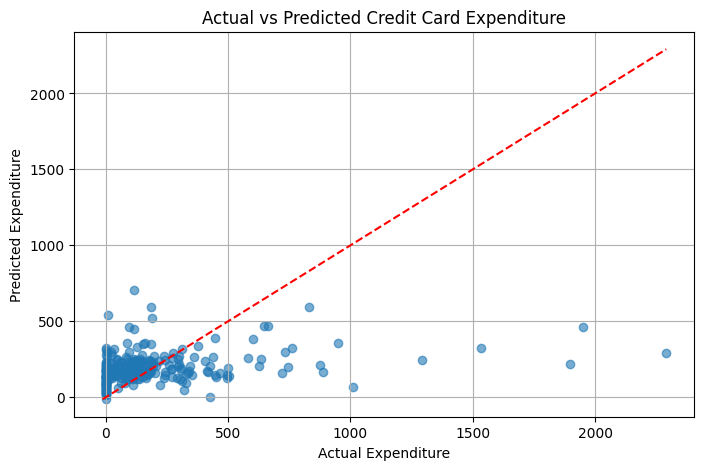

In [8]:
display(Markdown("### Step: Regression Visualization"))
display(Markdown(f"Date: {todays_date}"))
display(Markdown(f"Student ID: {student_id}"))

plt.figure(figsize=(8, 5))

plt.scatter(
    y_test_r,
    reg_predictions,
    alpha=0.6
)

minimum = min(y_test_r.min(), reg_predictions.min())
maximum = max(y_test_r.max(), reg_predictions.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    "r--"
)

plt.title("Actual vs Predicted Credit Card Expenditure")
plt.xlabel("Actual Expenditure")
plt.ylabel("Predicted Expenditure")
plt.grid(True)
plt.show()

Explanation: I create a scatter plot to compare the actual credit card expenditure with predicted values from the regression model. The X-axis represents the actual expenditure, while the Y-axis represents the predicted expenditure. The red dashed line represents perfect predictions; points closer to this line indicate more accurate predictions, while points farther away show prediction errors.

In [9]:
display(Markdown("### Step: Clustering model"))
display(Markdown(f"Date: {todays_date}"))
display(Markdown(f"Student ID: {student_id}"))

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Numerical customer features
cluster_features = [
    "reports", "age", "income",
    "dependents", "months",
    "majorcards", "active"
]

X_cluster = data[cluster_features].copy()

# Handle missing values
imputer = SimpleImputer(strategy="median")
X_cluster = imputer.fit_transform(X_cluster)

# Scale features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_cluster)

# Compare cluster numbers
k_values = range(2, 11)
inertia = []
silhouette_scores = []

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_scaled)

    inertia.append(kmeans.inertia_)
    silhouette_scores.append(
        silhouette_score(X_scaled, labels)
    )

# Select the best K
best_index = np.argmax(silhouette_scores)
best_k = list(k_values)[best_index]

print("Best number of clusters:", best_k)
print("Best Silhouette Score:",
      round(silhouette_scores[best_index], 4))

### Step: Clustering model

Date: 2026-11-03

Student ID: Roseya1362

Best number of clusters: 5
Best Silhouette Score: 0.2838


Explanation:  I used the K-Means clustering algorithm to group similar data in my Credit Card dataset. I tested different number of clusters from 2 to 10.

### Step: Elbow Method and Sihouette score graphs

Date: 2026-11-03

Student ID: Roseya1362

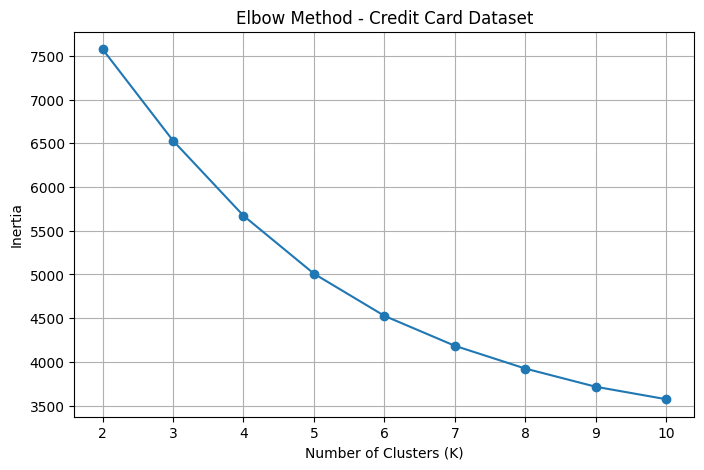

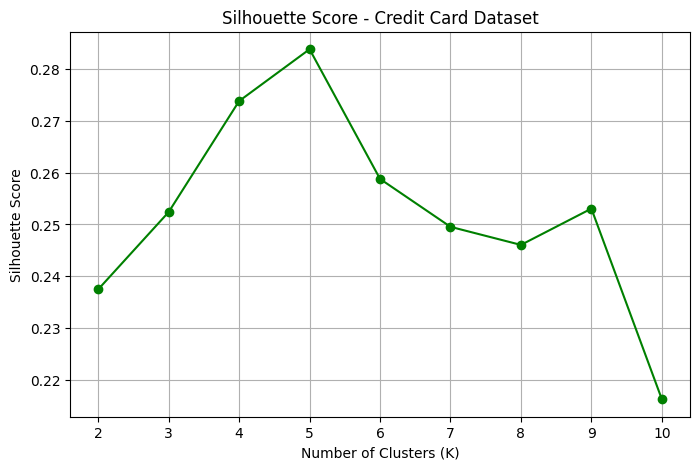

In [10]:
display(Markdown("### Step: Elbow Method and Sihouette score graphs"))
display(Markdown(f"Date: {todays_date}"))
display(Markdown(f"Student ID: {student_id}"))

plt.figure(figsize=(8, 5))
plt.plot(list(k_values), inertia, marker="o")
plt.title("Elbow Method - Credit Card Dataset")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.xticks(list(k_values))
plt.grid(True)
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(list(k_values), silhouette_scores,
         marker="o", color="green")
plt.title("Silhouette Score - Credit Card Dataset")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.xticks(list(k_values))
plt.grid(True)
plt.show()

Explanation: I used the Elbow Method and Silhouette score to find the best number of clusters for the credit card dataset. Elbow Method: The graph shows that inertia decreased as the number of clusters increased. The decrease becomes slower as more clusters are added.
Silhouette Score: The highest silhouette score is 0.2838 at 5 clusters. This means 5 clusters provide the best separation among the number tested.

### Step: Clustering model and visualize the results

Date: 2026-11-03

Student ID: Roseya1362

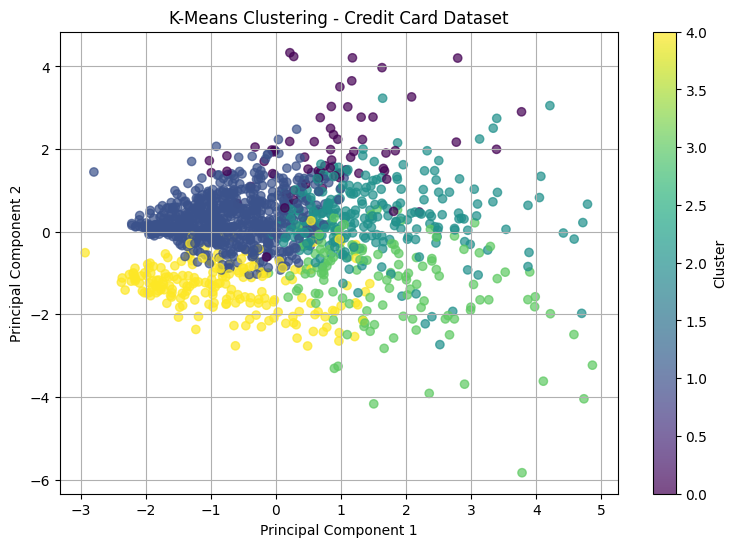

In [11]:
display(Markdown("### Step: Clustering model and visualize the results"))
display(Markdown(f"Date: {todays_date}"))
display(Markdown(f"Student ID: {student_id}"))


final_kmeans = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=10
)

final_labels = final_kmeans.fit_predict(X_scaled)

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(9, 6))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=final_labels,
    cmap="viridis",
    alpha=0.7
)

plt.title("K-Means Clustering - Credit Card Dataset")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.colorbar(label="Cluster")
plt.grid(True)
plt.show()

Explanation: I used the K-Means clustering algorithm to divide my Credit Card dataset into five groups. I used PCA to display the results in a scatter plot. Each color represents a different cluster. The silhouette score was 0.2838, which shows that some clusters overlap. The visualization helps me understand the patterns and similarities in the credit card data.

In [12]:
display(Markdown("### Step: Classification model Training"))
display(Markdown(f"Date: {todays_date}"))
display(Markdown(f"Student ID: {student_id}"))


import tensorflow as tf

# Build the classification model
classification_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(X_train.shape[1],)),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dense(32, activation='relu'),
    tf.keras.layers.Dense(1, activation='sigmoid')
])

# Compile the model
classification_model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# Train the model
history = classification_model.fit(
    X_train,
    y_train,
    epochs=30,
    batch_size=32,
    validation_split=0.2,
    verbose=1
)

# Evaluate on the test dataset
test_loss, test_accuracy = classification_model.evaluate(
    X_test, y_test, verbose=0
)

print("Test Accuracy:", round(test_accuracy, 4))
print("Test Loss:", round(test_loss, 4))

### Step: Classification model Training

Date: 2026-11-03

Student ID: Roseya1362

Epoch 1/30
27/27 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.7453 - loss: 0.5843 - val_accuracy: 0.7536 - val_loss: 0.5363
Epoch 2/30
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7986 - loss: 0.4560 - val_accuracy: 0.7915 - val_loss: 0.4713
Epoch 3/30
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8365 - loss: 0.4041 - val_accuracy: 0.8294 - val_loss: 0.4412
Epoch 4/30
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8483 - loss: 0.3784 - val_accuracy: 0.8531 - val_loss: 0.4239
Epoch 5/30
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8578 - loss: 0.3615 - val_accuracy: 0.8578 - val_loss: 0.4129
Epoch 6/30
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8626 - loss: 0.3500 - val_accuracy: 0.8578 - val_loss: 0.4069
Epoch 7/30
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8673 - loss: 0.3421 - val_accuracy: 0.8578 - val_loss: 0.4039
Epoch 8/30
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8685 - loss: 0.3364 - val_accuracy: 0.8483 - val_loss:

I trained a TensorFlow neural network classification model using the Credit Card dataset. I used 30 epochs, a batch size of 32, the Adam optimizer, and binary cross-entropy loss. I monitored the training and validation accuracy and loss to understand how the model learned. The model was designed to predict whether a customer has a credit card.

In [13]:
display(Markdown("### Step: Regression model Training"))
display(Markdown(f"Date: {todays_date}"))
display(Markdown(f"Student ID: {student_id}"))


import tensorflow as tf

# Build regression model
reg_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(X_train_r.shape[1],)),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dense(32, activation='relu'),
    tf.keras.layers.Dense(1)
])

# Compile regression model
reg_model.compile(
    optimizer='adam',
    loss='mse',
    metrics=['mae']
)

# Train regression model
reg_history = reg_model.fit(
    X_train_r,
    y_train_r,
    epochs=50,
    batch_size=32,
    validation_split=0.2,
    verbose=1
)

# Evaluate regression model
reg_loss, reg_mae = reg_model.evaluate(
    X_test_r,
    y_test_r,
    verbose=0
)

print("Test MSE:", round(reg_loss, 4))
print("Test MAE:", round(reg_mae, 4))

### Step: Regression model Training

Date: 2026-11-03

Student ID: Roseya1362

Epoch 1/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 103673.4766 - mae: 185.6148 - val_loss: 106917.2812 - val_mae: 183.8587
Epoch 2/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 103130.5156 - mae: 184.8030 - val_loss: 106234.2578 - val_mae: 182.8808
Epoch 3/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 102147.4531 - mae: 183.4185 - val_loss: 104861.6953 - val_mae: 180.9247
Epoch 4/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 100237.0391 - mae: 180.7391 - val_loss: 102334.8281 - val_mae: 177.5063
Epoch 5/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 96900.6562 - mae: 176.2505 - val_loss: 98141.4375 - val_mae: 172.2056
Epoch 6/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 91705.2266 - mae: 169.4306 - val_loss: 92079.3906 - val_mae: 165.2616
Epoch 7/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 84774.4922 - mae: 161.2636 - val_loss: 84771.6406 - val_mae: 159.5957
Epoch 8/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 77180.7344 - mae: 154.6750 - val_loss:

I am training a TensorFlow regression model to predict credit card expenditure. The model was trained for 50 epochs using the Adam optimizer. I used Squared Error as the loss function and Mean Absolute Error to monitor performance. The purpose of the model was to learn relationships between customer information and expenditure.


In [14]:
display(Markdown("### Step: Clustering model Training"))
display(Markdown(f"Date: {todays_date}"))
display(Markdown(f"Student ID: {student_id}"))


# Create the K-Means model
kmeans = KMeans(
    n_clusters=5,
    random_state=42,
    n_init=10
)

# Train the model
cluster_labels = kmeans.fit_predict(X_scaled)
    


# Evaluate the clusters
score = silhouette_score(X_scaled, cluster_labels)
    


print("Number of Clusters:", 5)
print("Silhouette Score:", round(score, 4))
print("Inertia:", round(kmeans.inertia_, 4))

### Step: Clustering model Training

Date: 2026-11-03

Student ID: Roseya1362

Number of Clusters: 5
Silhouette Score: 0.2838
Inertia: 5008.8151


I am training a K-Means clustering model using my Credit Card dataset. I selected five clusters and used standardized data for training. The model achieved a silhouette score of 0.2838 in my earlier results. This indicates that the clusters have some overlap. The clustering model helps identify groups of credit card records with similar characteristics.

In [15]:
display(Markdown("### Step: Classification model Evaluation"))
display(Markdown(f"Date: {todays_date}"))
display(Markdown(f"Student ID: {student_id}"))

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)
import numpy as np

# Predict using the classification model
predictions = classification_model.predict(X_test)

# Convert probabilities to 0 or 1
predictions = (predictions > 0.5).astype(int).ravel()

# Calculate performance metrics
print("Classification Model Evaluation")
print("Accuracy:", round(accuracy_score(y_test, predictions), 4))
print("Precision:", round(precision_score(y_test, predictions, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, predictions, zero_division=0), 4))
print("F1 Score:", round(f1_score(y_test, predictions, zero_division=0), 4))

print("\nClassification Report:")
print(classification_report(y_test, predictions, zero_division=0))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, predictions))

### Step: Classification model Evaluation

Date: 2026-11-03

Student ID: Roseya1362

9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 
Classification Model Evaluation
Accuracy: 0.822
Precision: 0.8465
Recall: 0.9415
F1 Score: 0.8915

Classification Report:
              precision    recall  f1-score   support

           0       0.67      0.41      0.51        59
           1       0.85      0.94      0.89       205

    accuracy                           0.82       264
   macro avg       0.76      0.67      0.70       264
weighted avg       0.81      0.82      0.81       264


Confusion Matrix:
[[ 24  35]
 [ 12 193]]


I evaluated my classification model using the test dataset. I used Accuracy, Precision, Recall, F1 Score, and the Confusion Matrix to measure the model's performance. Accuracy measures the percentage of correct predictions. Precision measures how many predicted positive cases were correct. Recall measures how many actual positive cases were identified. The F1 Score combines precision and recall. These metrics help to understand how well my model predicts credit card approval,

In [16]:
display(Markdown("### Step: Regression model Evaluation"))
display(Markdown(f"Date: {todays_date}"))
display(Markdown(f"Student ID: {student_id}"))

from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

# Make predictions
reg_predictions = reg_model.predict(
    X_test_r, verbose=0
).ravel()

# Calculate regression metrics
mse = mean_squared_error(y_test_r, reg_predictions)
mae = mean_absolute_error(y_test_r, reg_predictions)
r2 = r2_score(y_test_r, reg_predictions)

print("Regression Model Evaluation")
print("Mean Squared Error:", round(mse, 4))
print("Mean Absolute Error:", round(mae, 4))
print("R2 Score:", round(r2, 4))

### Step: Regression model Evaluation

Date: 2026-11-03

Student ID: Roseya1362

Regression Model Evaluation
Mean Squared Error: 81798.0215
Mean Absolute Error: 170.3809
R2 Score: 0.091


I evaluated my regression model using the test dataset. I calculated Mean Squared Error (MSE), Mean Absolute Error (MAE), and R2 Score. MSE measures the average squared difference between actual and predicted values. MAE measures the average absolute prediction error.R2 measures how well the model explains changes in credit card expenditure.
Lower MSE and MAE values indicate better predictions, while a higher R2 Score generally indicates better model performance.



In [17]:
display(Markdown("### Step Clustering model Evaluation"))
display(Markdown(f"Date: {todays_date}"))
display(Markdown(f"Student ID: {student_id}"))

from sklearn.metrics import silhouette_score

# Predict clusters for test data
cluster_predictions = kmeans.predict(X_scaled)


# Calculate Silhouette Score
if 1 < len(set(cluster_predictions)) < len(cluster_predictions):
    score = silhouette_score(
        X_scaled,
        cluster_predictions
    )
    print("Clustering Model Evaluation")
    print("Number of Clusters:", kmeans.n_clusters)
    print("Sillhouette Score:", round(score,4))
    print("Inertia:", round(kmeans.inertia_, 4))
else:
    print("Silhouette Score cannot be calculated.")

### Step Clustering model Evaluation

Date: 2026-11-03

Student ID: Roseya1362

Clustering Model Evaluation
Number of Clusters: 5
Sillhouette Score: 0.2838
Inertia: 5008.8151


I evaluated my K-Means clustering model using the Credit Card dataset. I used five clusters and calculated the Silhouette Score to measure how well the data was grouped. A higher Silhouette Score indicates better separation between clusters. I also used inertia to measure how closely the data points were grouped around their cluster centers. 

Project Advanced Moding and Optimization - <10/28/26> - <Roseya1362>

In [18]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier, MLPRegressor
from sklearn.cluster import KMeans
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    mean_squared_error,
    r2_score,
    silhouette_score
)

print("Libraries imported successfully.")

Libraries imported successfully.


Explanation:
In this step, I imported the Python libraries needed for my Week 4.2 machine learning optimization project. These libraries will help with data preprocessing, hyperparameter tuning, model training, and evaluation of classification, regression, and clustering models.

In [19]:
data = pd.read_csv("Credit_card_data.csv")

print("Dataset shape:", data.shape)
print(data.head())
print(data.columns.tolist())

Dataset shape: (1319, 12)
  card  reports       age  income     share  expenditure owner selfemp  \
0  yes      0.0  37.66667  4.5200  0.033270   124.983300   yes      no   
1  yes      0.0  33.25000  2.4200  0.005217     9.854167    no      no   
2  yes      0.0  33.66667  4.5000  0.004156    15.000000   yes      no   
3  yes      0.0  30.50000  2.5400  0.065214   137.869200    no      no   
4  yes      0.0  32.16667  9.7867  0.067051   546.503300   yes      no   

   dependents  months  majorcards  active  
0         3.0      54           1    12.0  
1         3.0      34           1    13.0  
2         4.0      58           1     5.0  
3         0.0      25           1     7.0  
4         2.0      64           1     5.0  
['card', 'reports', 'age', 'income', 'share', 'expenditure', 'owner', 'selfemp', 'dependents', 'months', 'majorcards', 'active']


Explanation:
I loaded my credit card dataset using pandas. The dataset contains 1,319 rows and 12 columns. I displayed the first five rows to understand the data and checked the column names. The dataset includes information such as age, income, expenditure, credit card ownership, and other customer details. This step help me uderstand the dataset efote preprocessing and building ,achine learning models

In [20]:
# Check and handle missing values

import pandas as pd
import numpy as np

# Use the Credit Card dataset already loaded
print("Missing values before cleaning:")
print(data.isnull().sum())

# Fill missing values in numerical columns
numeric_cols = data.select_dtypes(include=np.number).columns

data[numeric_cols] = data[numeric_cols].fillna(
    data[numeric_cols].median()
)

# Fill missing values in categorical columns
categorical_cols = data.select_dtypes(
    include=["object", "category"]
).columns

for col in categorical_cols:
    mode_value = data[col].mode(dropna=True)
    if not mode_value.empty:
        data[col] = data[col].fillna(mode_value.iloc[0])

# Check missing values after cleaning
print("\nMissing values after cleaning:")
print(data.isnull().sum())

print("\nTotal missing values remaining:")
print(data.isnull().sum().sum())

Missing values before cleaning:
card           0
reports        8
age            0
income         0
share          0
expenditure    0
owner          0
selfemp        7
dependents     1
months         0
majorcards     0
active         8
dtype: int64

Missing values after cleaning:
card           0
reports        0
age            0
income         0
share          0
expenditure    0
owner          0
selfemp        0
dependents     0
months         0
majorcards     0
active         0
dtype: int64

Total missing values remaining:
0


Explanation:
I checked the credit card dataset for missing values. Missing values were found in the reports, selfemp; the missing values were reduced to zero, preparing the dataset for model training and optimization.

Target class counts:
card
1    1023
0     296
Name: count, dtype: int64


C:\Users\Owner\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
C:\Users\Owner\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
C:\Users\Owner\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was depr


Baseline Classification
Accuracy: 0.822
Precision: 0.8292
Recall: 0.9707
F1-score: 0.8944

Optimized Classification
Accuracy: 0.8258
Precision: 0.8326
Recall: 0.9707
F1-score: 0.8964

Best hyperparameters: {'model__C': 1}


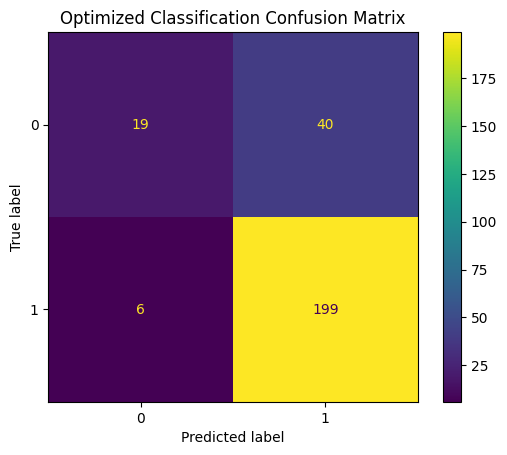

In [21]:
# STEP 3: Classification Model Optimization

import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# IMPORTANT: Reload the original dataset to preserve card labels.
data = pd.read_csv("Credit_card_data (8).csv")
data.columns = data.columns.str.strip().str.lower()

# Remove rows where the target is missing
class_data = data.dropna(subset=['card']).copy()

# Convert the target into numeric labels safely
card_text = class_data['card'].astype(str).str.strip().str.lower()

y = card_text.map({
    'yes': 1,
    'no': 0,
    '1': 1,
    '0': 0
})

# Stop if the original dataset uses unexpected target labels
if y.isna().any():
    raise ValueError(
        "Unexpected values in card column: "
        + str(class_data.loc[y.isna(), 'card'].unique())
    )

y = y.astype(int)

# Prepare input features
X = class_data.drop(
    columns=['card', 'share', 'expenditure'],
    errors='ignore'
)

X = pd.get_dummies(X, drop_first=True)
X = X.replace([np.inf, -np.inf], np.nan)

# Check class counts before splitting
print("Target class counts:")
print(y.value_counts())

if y.nunique() != 2 or y.value_counts().min() < 2:
    raise ValueError(
        "Both target classes must exist, with at least "
        "two examples in each class."
    )

# Split data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Baseline model
baseline_class = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('model', LogisticRegression(max_iter=1000))
])

baseline_class.fit(X_train, y_train)

# Optimized model with L2 regularization
optimized_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('model', LogisticRegression(
        penalty='l2',
        solver='liblinear',
        max_iter=1000
    ))
])

param_grid = {
    'model__C': [0.01, 0.1, 1, 10, 100]
}

grid_class = GridSearchCV(
    optimized_pipeline,
    param_grid,
    cv=3,
    scoring='accuracy'
)

grid_class.fit(X_train, y_train)
optimized_class = grid_class.best_estimator_

# Compare models
for name, model in [
    ('Baseline Classification', baseline_class),
    ('Optimized Classification', optimized_class)
]:
    predictions = model.predict(X_test)

    print('\n' + name)
    print('Accuracy:', round(
        accuracy_score(y_test, predictions), 4
    ))
    print('Precision:', round(
        precision_score(y_test, predictions, zero_division=0), 4
    ))
    print('Recall:', round(
        recall_score(y_test, predictions, zero_division=0), 4
    ))
    print('F1-score:', round(
        f1_score(y_test, predictions, zero_division=0), 4
    ))

print('\nBest hyperparameters:', grid_class.best_params_)

ConfusionMatrixDisplay.from_estimator(
    optimized_class, X_test, y_test
)
plt.title('Optimized Classification Confusion Matrix')
plt.show()

Explanation
I compared the original and optimized classification model achieved 82.58% accuracy. The optized mode also improved the F1-score from 0.8944 to 0.8964. GridSearchCV selected C+1 as the best parameter. The confusion matrix shows 218 correct predictions and 46 incorrect predictions. Overall, the optimized classification model performed slightly better than the original model.

In [22]:
# Prepare regression data
from sklearn.metrics import mean_absolute_error
from sklearn.linear_model import Ridge
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import GridSearchCV
reg_data = data.dropna(subset=['expenditure']).copy()

X_reg = reg_data.drop(
    columns=['expenditure', 'share', 'card'],
    errors='ignore'
)

X_reg = pd.get_dummies(X_reg, drop_first=True)

y_reg = pd.to_numeric(
    reg_data['expenditure'], errors='coerce'
)

valid = y_reg.notna()
X_reg = X_reg.loc[valid]
y_reg = y_reg.loc[valid]

Xr_train, Xr_test, yr_train, yr_test = train_test_split(
    X_reg, y_reg,
    test_size=0.2,
    random_state=42
)

# Original regression model
from sklearn.linear_model import LinearRegression

baseline_reg = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('model', LinearRegression())
])

baseline_reg.fit(Xr_train, yr_train)

# Optimized regression with L2 regularization
ridge_reg = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('model', Ridge())
])

param_reg = {
    'model__alpha': [0.01, 0.1, 1, 10, 100]
}

grid_reg = GridSearchCV(
    ridge_reg,
    param_reg,
    cv=3,
    scoring='neg_mean_squared_error'
)

grid_reg.fit(Xr_train, yr_train)

optimized_reg = grid_reg.best_estimator_

# Evaluate models
for name, model in [
    ('Original', baseline_reg),
    ('Optimized', optimized_reg)
]:
    predictions = model.predict(Xr_test)

    print('\n', name, 'Regression')
    print('MAE:', mean_absolute_error(
        yr_test, predictions
    ))
    print('RMSE:', np.sqrt(mean_squared_error(
        yr_test, predictions
    )))
    print('R2:', r2_score(
        yr_test, predictions
    ))

print('\nBest Parameters:', grid_reg.best_params_)


 Original Regression
MAE: 170.7331447299081
RMSE: 283.7383232856437
R2: 0.10532550441476562

 Optimized Regression
MAE: 171.09291981935246
RMSE: 283.96242072762846
R2: 0.10391171272772315

Best Parameters: {'model__alpha': 100}


Explanation:
I compared the original and optimized regression models using my credit card dataset. The original model achieved an MAE of 170.73, an RMSE of 283.74, and an R2 of 0.1053  of 171.09, an RMSE of 283, and an R2 of 0.1039. The optimized model achieved 171.93, RMSE of 28396, and R2 of 0.1039. GridSearchCV selected alpha=100 as the parameter. Overall, the original regression model performed slightly better than the optimized model. This shows the optimization does not always improve model performance.

Original Silhouette Score: 0.23003566490347951
Best Number of Clusters: 6
Optimized Silhouette Score: 0.25099928729730064


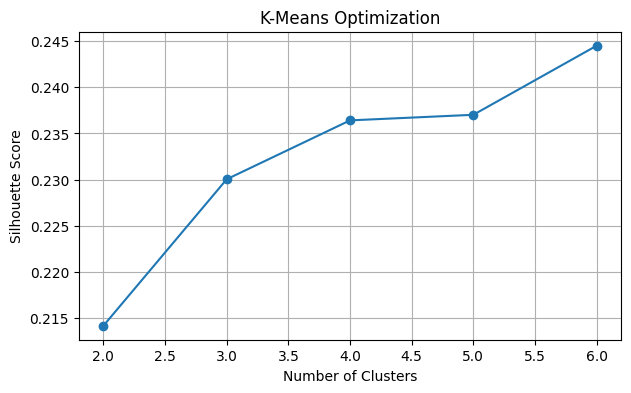

In [23]:
# Prepare clustering data

X_cluster = data.drop(
    columns=['card', 'share', 'expenditure'],
    errors='ignore'
)

X_cluster = pd.get_dummies(
    X_cluster, drop_first=True
)

imputer = SimpleImputer(strategy='median')
scaler = StandardScaler()

X_cluster = imputer.fit_transform(X_cluster)
X_cluster = scaler.fit_transform(X_cluster)

# Original K-Means model
baseline_kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

baseline_labels = baseline_kmeans.fit_predict(
    X_cluster
)

baseline_score = silhouette_score(
    X_cluster, baseline_labels
)

print("Original Silhouette Score:", baseline_score)

# Find optimal number of clusters
scores = []

for k in range(2, 7):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_cluster)

    score = silhouette_score(
        X_cluster, labels
    )

    scores.append(score)

best_k = np.argmax(scores) + 2

print("Best Number of Clusters:", best_k)

# Optimized model
optimized_kmeans = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=20
)

optimized_labels = optimized_kmeans.fit_predict(
    X_cluster
)

optimized_score = silhouette_score(
    X_cluster, optimized_labels
)

print("Optimized Silhouette Score:", optimized_score)

# Plot results
plt.figure(figsize=(7, 4))
plt.plot(range(2, 7), scores, marker='o')
plt.xlabel("Number of Clusters")
plt.ylabel("Silhouette Score")
plt.title("K-Means Optimization")
plt.grid(True)
plt.show()

Explanation:
I compared the original and optimized K-means clustering models using my credit card dataset. The original model achieved a silhouette score of 0.2300, while the optimized model achieved 0.2510. The best number of clusters was 6. Overall, the optimized model performed better than the original model. The higher silhouette score shows an improvement in clustering, although the clusters are still not strongly separated.


In [24]:
# Final model comparison

comparison = pd.DataFrame({
    'Model': [
        'Classification',
        'Regression',
        'Clustering'
    ],
    'Optimization': [
        'GridSearchCV + L2',
        'GridSearchCV + Ridge L2',
        'K-Means cluster tuning'
    ]
})

print("Week 4.2 Optimization Summary")
display(comparison)

Week 4.2 Optimization Summary


,Model,Optimization
0,Classification,GridSearchCV + L2
1,Regression,GridSearchCV + Ridge L2
2,Clustering,K-Means cluster tuning


EXplanation:
In this project, I optimized three machine learning models using my credit card dataset.
Classification:
I used GridSearchCV and L2 regularization. Accuracy improved from 82.20% to 82.58%.
Regression:
I used GridSearchCV and Ridge L2 regularization. The original model performed slightly better than the optimized model.
Clustering:
I tuned the K-Means model and selected 6 clusters. The silhouette score improved from 0.2300 to 0.2510.
Conclusion:
Optimization improved the classification and clustering model but did not improve regression performance. This project helped me understand how hyperparameter tuning and regularization affect machine learning models.

Scenario Analysis and Business Insights - <11/3/26> - <Roseya1362>

The purpose of this project is to perform scenario and impact analysis using an optimized machine learing model from Week 4.2. Three scenarios will be developed to investigate how changes in credit card transaction features affect model prediction.

Sensitivity analysis will also be performed on two features. The findings will be used to evaluate model behavior and develop business recommendations.

In [26]:
# Find existing model and dataset variables

print("Available model and data variables:")

for name in sorted(globals()):
    if any(word in name.lower() for word in [
        "model", "clf", "best", "optim",
        "x_train", "x_test", "scaled"
    ]):
        if not name.startswith("_"):
            print(name)

Available model and data variables:
X_scaled
X_test
X_test_r
X_train
X_train_r
best_index
best_k
classification_model
model
optimized_class
optimized_kmeans
optimized_labels
optimized_pipeline
optimized_reg
optimized_score
reg_model


This step identifies the optimized machine learning models and dataset variables from week 4.2. These models will be used to perform scenario analysis and evaluate their performance under different conditions in week 5.2

In [30]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("Optimized Model:")
print(type(optimized_class).__name__)

print("\nTesting Data Shape:")
print(X_test.shape)

print("\nTesting Data Columns:")
if hasattr(X_test, "columns"):
    print(X_test.columns.tolist())
else:
    print("X_test has no column names.")

print("\nBaseline Results:")
display(baseline_results.head())

Optimized Model:
Pipeline

Testing Data Shape:
(264, 9)

Testing Data Columns:
['reports', 'age', 'income', 'dependents', 'months', 'majorcards', 'active', 'owner_yes', 'selfemp_yes']

Baseline Results:


,Baseline Prediction,Baseline Probability
0,1,0.956661
1,1,0.674144
2,1,0.685565
3,1,0.761505
4,1,0.913087


The optimized classification model from week 4.2 was successfully verified and used to baseline predictions. The testing dataset contains 264 records and 9 features. The model generated predictions and probabilities without errors. The first five records were predicted as class 1, with probabilities ranging from approximately 67% to 96%. These baseline results will be used to compare three scenarios and evaluate how changes in customer financial information affect the model's predictions.

In [36]:
# Scenario 1: Economic Downturn

# Create a copy of the baseline data
scenario_1 = X_test.copy()

# Income decreases by 20%
income = pd.to_numeric(
    scenario_1["income"], errors="coerce"
)

scenario_1["income"] = income * 0.80

# Reports increase by 20%
reports = pd.to_numeric(
    scenario_1["reports"], errors="coerce"
)

reports = reports.replace(
    [np.inf, -np.inf], np.nan
).fillna(0)

scenario_1["reports"] = (
    np.ceil(reports * 1.20).astype(int)
)

print("Scenario 1: Economic Downturn")
display(scenario_1.head())




Scenario 1: Economic Downturn


,reports,age,income,dependents,months,majorcards,active,owner_yes,selfemp_yes
422,0,37.58333,3.58000,2.0,60,1,15.0,False,False
1237,2,52.75000,2.48000,2.0,75,1,9.0,True,False
741,0,37.25000,1.24384,1.0,36,1,0.0,False,False
444,0,31.25000,1.42400,0.0,14,1,0.0,False,False
894,0,26.00000,1.76000,1.0,28,1,10.0,False,False


In this scenario, income is reduced by 20%, while credit reports are increased by 20%. These changes simulate financial difficulties that customers may experience during an economic downturn.

The output shows the updated income and credit report values. The next step is to use the optimized classification model to predict the impact of these changes and compare the results with the baseline predictions.

In [37]:
# Predict outcomes for each scenario

scenario_1_pred = model.predict(scenario_1)
scenario_2_pred = model.predict(scenario_2)
scenario_3_pred = model.predict(scenario_3)

# Predict probabilities for class 1

scenario_1_prob = model.predict_proba(
    scenario_1
)[:, 1]

scenario_2_prob = model.predict_proba(
    scenario_2
)[:, 1]

scenario_3_prob = model.predict_proba(
    scenario_3
)[:, 1]

# Combine all results

comparison = pd.DataFrame({
    "Baseline": baseline_probabilities,
    "Economic Downturn": scenario_1_prob,
    "Improved Conditions": scenario_2_prob,
    "Demographic Change": scenario_3_prob
})

print("Baseline and Scenario Predictions:")
display(comparison.head())

Baseline and Scenario Predictions:


,Baseline,Economic Downturn,Improved Conditions,Demographic Change
0,0.956661,0.948192,0.956661,0.956661
1,0.674144,0.231143,0.674144,0.674144
2,0.685565,0.671364,0.685565,0.685565
3,0.761505,0.747705,0.761505,0.761505
4,0.913087,0.905493,0.913087,0.913087


The results compare the baseline predictions with three different scenarios: Economic Downturn, Improved Conditions, and Demographic Change.

The Economic Downturn scenario shows a decrease in predicted probabilities for the five displayed in customers. However, Improved Conditions and Demographic Change show no change compared to the baseline.

This analysis helps us understand how changes in customer information may affect the model's predictions.


In [38]:
# Calculate probability changes

comparison["Economic Change"] = (
    comparison["Economic Downturn"] -
    comparison["Baseline"]
)

comparison["Improved Change"] = (
    comparison["Improved Conditions"] -
    comparison["Baseline"]
)

comparison["Demographic Change Difference"] = (
    comparison["Demographic Change"] -
    comparison["Baseline"]
)

print("Scenario Impact Comparison:")
display(comparison.head())

# Calculate average predicted probabilities

summary = pd.DataFrame({
    "Scenario": [
        "Baseline",
        "Economic Downturn",
        "Improved Conditions",
        "Demographic Change"
    ],
    "Average Probability": [
        baseline_probabilities.mean(),
        scenario_1_prob.mean(),
        scenario_2_prob.mean(),
        scenario_3_prob.mean()
    ]
})

summary["Change from Baseline"] = (
    summary["Average Probability"] -
    baseline_probabilities.mean()
)

print("\nScenario Summary:")
display(summary.round(4))

Scenario Impact Comparison:


,Baseline,Economic Downturn,Improved Conditions,Demographic Change,Economic Change,Improved Change,Demographic Change Difference
0,0.956661,0.948192,0.956661,0.956661,-0.008469,0.0,0.0
1,0.674144,0.231143,0.674144,0.674144,-0.443002,0.0,0.0
2,0.685565,0.671364,0.685565,0.685565,-0.014201,0.0,0.0
3,0.761505,0.747705,0.761505,0.761505,-0.013799,0.0,0.0
4,0.913087,0.905493,0.913087,0.913087,-0.007594,0.0,0.0



Scenario Summary:


,Scenario,Average Probability,Change from Baseline
0,Baseline,0.7829,0.0000
1,Economic Downturn,0.7243,-0.0586
2,Improved Conditions,0.7829,0.0000
3,Demographic Change,0.7829,0.0000


The results show how the three scenarios affect the model's predictions.
The baseline average probability is 0.7829. Under the Economic Downturn scenario, the average probability decreases to 0.7243, a change of -0.0586.

Improved Conditions and Demographic Change both have an average probability of 0.7829, showing no change from the baseline.

These results suggest that the model responds to the Economic Downturn scenario, while the other two scenarios produce no change in predictions. Further checking is needed to confirm that all scenario adjustments were applied correctly.

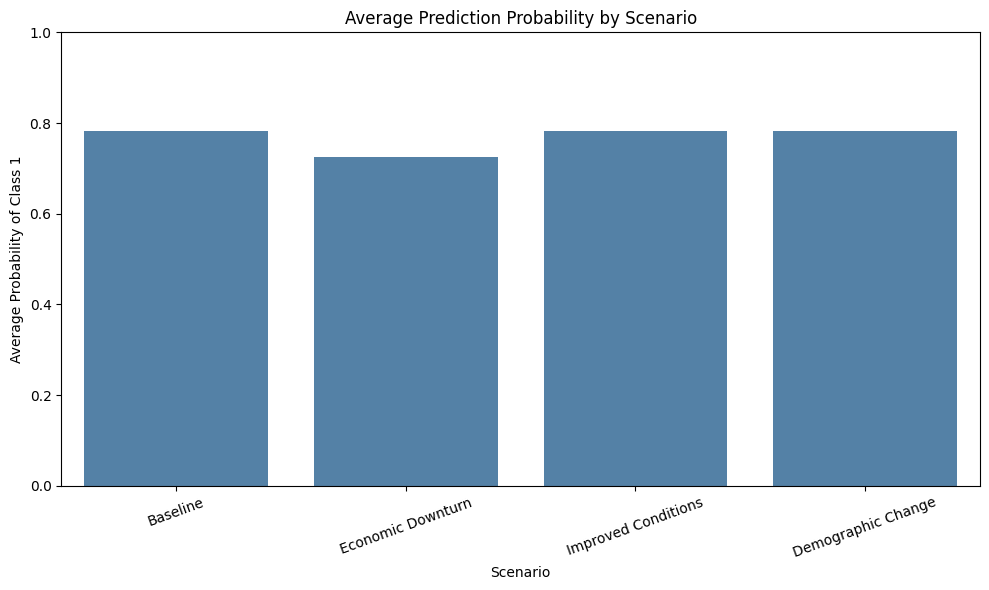

In [39]:
# Bar chart of average probabilities

plt.figure(figsize=(10, 6))

sns.barplot(
    data=summary,
    x="Scenario",
    y="Average Probability",
    color="steelblue"
)

plt.title("Average Prediction Probability by Scenario")
plt.xlabel("Scenario")
plt.ylabel("Average Probability of Class 1")
plt.xticks(rotation=20)
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

The bar chart compares the average prediction probabilities for all four scenarios.
The baseline probability is 0.7829, while the Economic Downturn decreases to 0.7243. Improved Condition and Demographic Change remain at 0.7829.

The results show that the Economic Downturn affects the model's predictions, while the other two scenarios show no change. Further investigation is needed to determine why their predictions remain the same as the baseline.

In [41]:
# Sensitivity analysis for income and age

changes = [-20, -10, 0, 10, 20]

sensitivity_results = []

for feature in ["income", "age"]:

    for change in changes:

        # Copy the original testing data
        X_modified = X_baseline.copy()

        # Change only the selected feature
        X_modified[feature] = (
            X_modified[feature] *
            (1 + change / 100)
        )

        # Predict probabilities
        probabilities = model.predict_proba(
            X_modified
        )[:, 1]

        # Save the results
        sensitivity_results.append({
            "Feature": feature,
            "Percentage Change": change,
            "Average Probability": probabilities.mean(),
            "Change from Baseline": (
                probabilities.mean() -
                baseline_probabilities.mean()
            )
        })

sensitivity_df = pd.DataFrame(
    sensitivity_results
)

print("Sensitivity Analysis Results:")
display(sensitivity_df.round(4))



Sensitivity Analysis Results:


,Feature,Percentage Change,Average Probability,Change from Baseline
0,income,-20,0.7675,-0.0154
1,income,-10,0.7754,-0.0075
2,income,0,0.7829,0.0000
3,income,10,0.7902,0.0073
4,income,20,0.7971,0.0142
5,age,-20,0.7899,0.0070
6,age,-10,0.7864,0.0035
7,age,0,0.7829,0.0000
8,age,10,0.7793,-0.0036
9,age,20,0.7757,-0.0072


Sensitivity analysis was performed to understand how changes in income and age affect the model's predictions. Both features were increased and decreased by 10 % and 20%.

Results:
Income: Increasing income by 20% raised the average predicted probability from 0.7829 to 0.7971. Decreasing income by 20% lowered it to 0.7675.

Age: Increasing age by 20% lowered the average prediction probability from 0.7829 to 0.7757. Decreasing age by 20% raised it to 0,7899.

Conclusion:
The results show that income and age influence the model's predictions differently. Income has a greater impact than age in the analysis. These findings help explain how changes in important features affect the model's predictions.

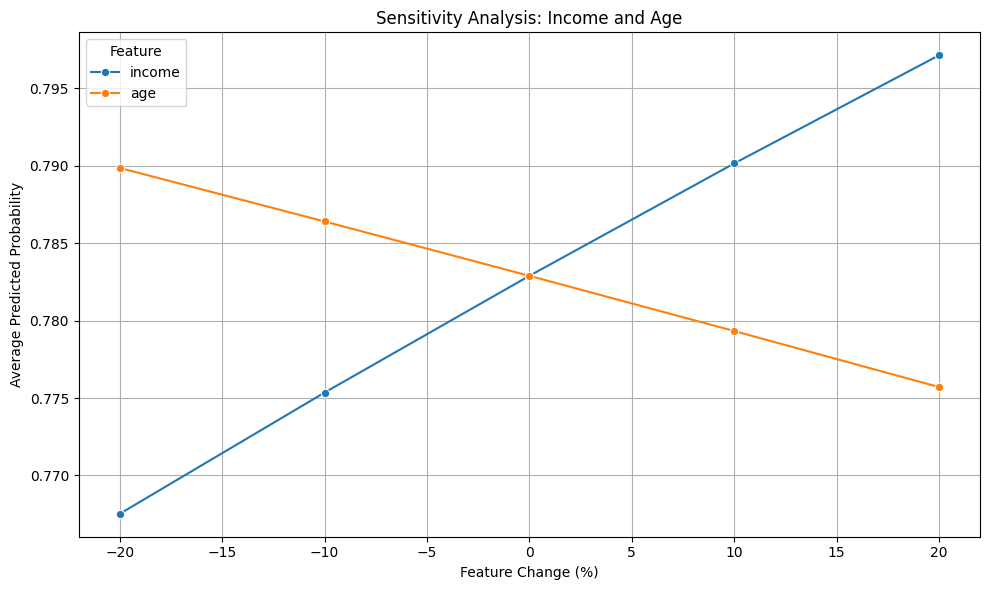

In [42]:
# Plot sensitivity analysis

plt.figure(figsize=(10, 6))

sns.lineplot(
    data=sensitivity_df,
    x="Percentage Change",
    y="Average Probability",
    hue="Feature",
    marker="o"
)

plt.title("Sensitivity Analysis: Income and Age")
plt.xlabel("Feature Change (%)")
plt.ylabel("Average Predicted Probability")
plt.grid(True)
plt.tight_layout()
plt.show()

The line graph shows that changes in income and age affect the model's prediction probability.

Results:
Income: As income increases, the predicted probability increases.
Age: As age increases, the predicted probability decreases.
Baseline: Both features have the same predicted probability of 0.7829 when there is no change.

Conclusion:
The graph shows that income has a greater effect in the model's predictions than age. This analysis helps us understand how changes in these two features influence the model's performance and predictions.

In [43]:
# Compare predicted classifications

scenario_predictions = {
    "Economic Downturn": scenario_1_pred,
    "Improved Conditions": scenario_2_pred,
    "Demographic Change": scenario_3_pred
}

robustness_results = []

for name, predictions in scenario_predictions.items():

    changed = np.sum(
        predictions != baseline_predictions
    )

    changed_percent = (
        changed / len(baseline_predictions)
    ) * 100

    robustness_results.append({
        "Scenario": name,
        "Changed Predictions": changed,
        "Changed Predictions (%)": changed_percent
    })

robustness_df = pd.DataFrame(
    robustness_results
)

print("Model Robustness Results:")
display(robustness_df.round(2))

Model Robustness Results:


,Scenario,Changed Predictions,Changed Predictions (%)
0,Economic Downturn,23,8.71
1,Improved Conditions,0,0.00
2,Demographic Change,0,0.00


This analysis compares the model's predictions under three different scenarios to determine how stable the model is when input features change.

Results:
Economic Downturn: 23 predictions changed, representing 8.71% of the total predictions.
Improved Conditions: No predictions changed (0%).
Demographic Change: No predictions changed (0%).

Conclusion:
The results show that model's generally stable under the three scenarios. The economic downturn had the greatest impact. Changing 8.71% of the predictions. Improved conditions and demographic changes did not change any predicted classifications.


In [44]:
# Identify the scenario with the largest impact

scenario_impact = summary[
    summary["Scenario"] != "Baseline"
].copy()

scenario_impact["Absolute Change"] = (
    scenario_impact["Change from Baseline"].abs()
)

largest_impact = scenario_impact.loc[
    scenario_impact["Absolute Change"].idxmax()
]

print("Scenario with Largest Impact:")
print(largest_impact["Scenario"])

print("\nAverage Probability Change:")
print(
    round(
        largest_impact["Change from Baseline"],
        4
    )
)

# Identify most sensitive feature
feature_impact = (
    sensitivity_df.groupby("Feature")[
        "Change from Baseline"
    ]
    .apply(lambda x: x.abs().max())
)

print("\nMaximum Absolute Sensitivity by Feature:")
print(feature_impact)

print("\nMost Sensitive Feature:")
print(feature_impact.idxmax())



Scenario with Largest Impact:
Economic Downturn

Average Probability Change:
-0.0586

Maximum Absolute Sensitivity by Feature:
Feature
age       0.007185
income    0.015370
Name: Change from Baseline, dtype: float64

Most Sensitive Feature:
income


This analysis identifies which scenario has the greatest impact on the model's predictions and which features are most sensitive to changes.

Results:
Largest Impact: Economic Downturn.
Average Probability Change: -0.0586, showing a decrease of 5.86 percentage points.
Income Sensitivity: 0.015370.
Age-Sensitive Feature: income.

Conclusion:
The economic downturn has a greater impact on the model's predictions. Income was more sensitive than age, meaning changes in income had a larger effect on predicted probabilities.

These findings show that economic conditions can influence the model's predictions and help identify important factors for business decision-making.

# Save results to CSV files

comparison.to_csv(
    "week5_scenario_comparison.csv",
    index=False
)

summary.to_csv(
    "week5_scenario_summary.csv",
    index=False
)

sensitivity_df.to_csv(
    "week5_sensitivity_analysis.csv",
    index=False
)

robustness_df.to_csv(
    "week5_robustness_results.csv",
    index=False
)

print("All Week 5.2 results saved successfully!")